In [32]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
from src.DistanceCalibration import *
from sklearn.mixture import GaussianMixture

%load_ext autoreload
%autoreload 2
calibration_folder = r'D:\data-distance-coding-project\calibration'

# set params for plots
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 14

colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


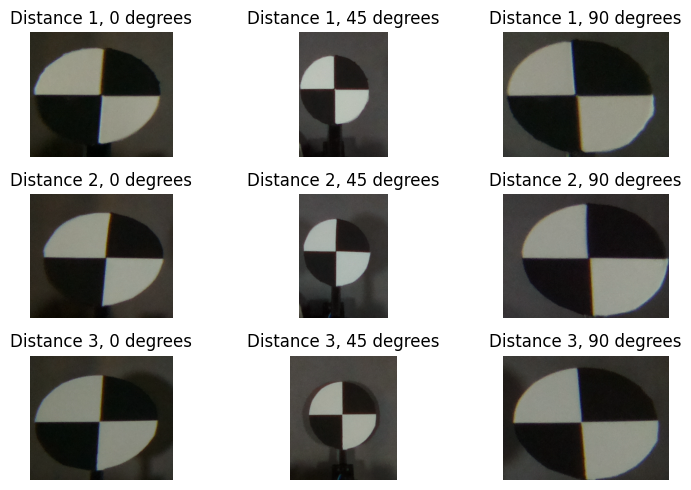

In [2]:
img_y = 850
img_x = [400, 1175, 1850]

y_offset = np.zeros((3, 3))
x_offset = np.zeros((3, 3))

x_offset[:, :] = 900
y_offset[:, 0] = 400
y_offset[:, 1] = 1200
y_offset[:, 2] = 1850

session = '240401'

image_1_00 = os.path.join(calibration_folder, session, 'distance_1_00.jpg')
image_1_45 = os.path.join(calibration_folder, session, 'distance_1_45.jpg')
image_1_90 = os.path.join(calibration_folder, session, 'distance_1_90.jpg')
image_1 = [image_1_00, image_1_45, image_1_90]

img_1_00 = cv2.imread(image_1_00)[850:1200, 400:800, :]
img_1_45 = cv2.imread(image_1_45)[850:1200, 1200:1450, :]
img_1_90 = cv2.imread(image_1_90)[850:1150, 1850:2250, :]
img_1 = [img_1_00, img_1_45, img_1_90]

image_2_00 = os.path.join(calibration_folder, session, 'distance_2_00.jpg')
image_2_45 = os.path.join(calibration_folder, session, 'distance_2_45.jpg')
image_2_90 = os.path.join(calibration_folder, session, 'distance_2_90.jpg')
image_2 = [image_2_00, image_2_45, image_2_90]

img_2_00 = cv2.imread(image_2_00)[850:1200, 400:800, :]
img_2_45 = cv2.imread(image_2_45)[850:1200, 1200:1450, :]
img_2_90 = cv2.imread(image_2_90)[850:1150, 1850:2250, :]
img_2 = [img_2_00, img_2_45, img_2_90]

image_3_00 = os.path.join(calibration_folder, session, 'distance_3_00.jpg')
image_3_45 = os.path.join(calibration_folder, session, 'distance_3_45.jpg')
image_3_90 = os.path.join(calibration_folder, session, 'distance_3_90.jpg')
image_3 = [image_3_00, image_3_45, image_3_90]

img_3_00 = cv2.imread(image_3_00)[850:1200, 400:800, :]
img_3_45 = cv2.imread(image_3_45)[850:1200, 1150:1450, :]
img_3_90 = cv2.imread(image_3_90)[850:1150, 1850:2250, :]
img_3 = [img_3_00, img_3_45, img_3_90]

fig, ax = plt.subplots(3, 3, figsize=(8, 5))
ax[0, 0].imshow(img_1[0])
ax[0,0].set_title('Distance 1, 0 degrees')
ax[0, 1].imshow(img_1[1])
ax[0,1].set_title('Distance 1, 45 degrees')
ax[0, 2].imshow(img_1[2])
ax[0,2].set_title('Distance 1, 90 degrees')

ax[1, 0].imshow(img_2[0])
ax[1,0].set_title('Distance 2, 0 degrees')
ax[1, 1].imshow(img_2[1])
ax[1,1].set_title('Distance 2, 45 degrees')
ax[1, 2].imshow(img_2[2])
ax[1,2].set_title('Distance 2, 90 degrees')

ax[2, 0].imshow(img_3[0])
ax[2,0].set_title('Distance 3, 0 degrees')
ax[2, 1].imshow(img_3[1])
ax[2,1].set_title('Distance 3, 45 degrees')
ax[2, 2].imshow(img_3[2])
ax[2,2].set_title('Distance 3, 90 degrees')

# set all axis to be off
for axi in ax.flatten():
    axi.axis('off')
    
plt.tight_layout()

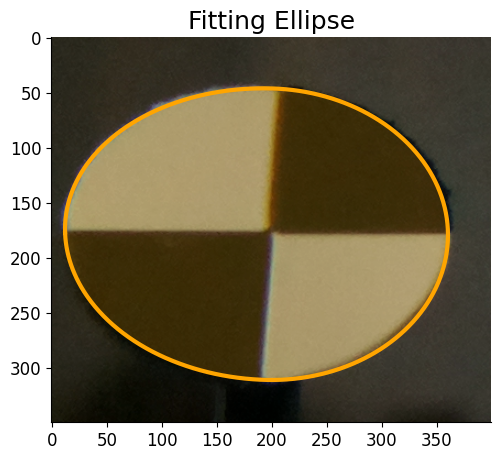

In [61]:
pts = get_contour(img_1[0], threshold = 115, show = False, approx = False, single_region = True)
ellipse, x_center, y_center, x_horizontal, y_horizontal, x_vertical, y_vertical = get_plot_features(img_1[0], threshold = 115)

plt.figure(figsize=(10, 5))
plt.imshow(img_1[0])
plt.plot(ellipse[:,0], ellipse[:,1], color = colors[0], linewidth = 3)
plt.fill(ellipse[:,0], ellipse[:,1], color = colors[0], alpha = 0.2)
# plt.scatter(pts[:,0], pts[:,1], color = colors[0], s = 5)
# plt.fill(pts[:,0], pts[:,1], color = colors[0], alpha = 0.1)
plt.title('Fitting Ellipse')
# set axis square
plt.gca().set_aspect('equal', adjustable='box')
# get rid of the box outlines of the spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
# plt.gca().spines['left'].set_visible(False)
# plt.gca().spines['bottom'].set_visible(False)
# plt.plot(x_horizontal, y_horizontal, c = 'b', linewidth = 3)
# plt.plot(x_vertical, y_vertical, c = 'b', linewidth = 3)
# plt.scatter(x_center, y_center, s = 100, c = 'b', marker = 'x')
# plt.plot(xy_quadrant[:,0], xy_quadrant[:,1], c = 'r', linewidth = 3)
# plt.gca().invert_yaxis()



Text(0.5, 1.0, 'Fitting quadrants')

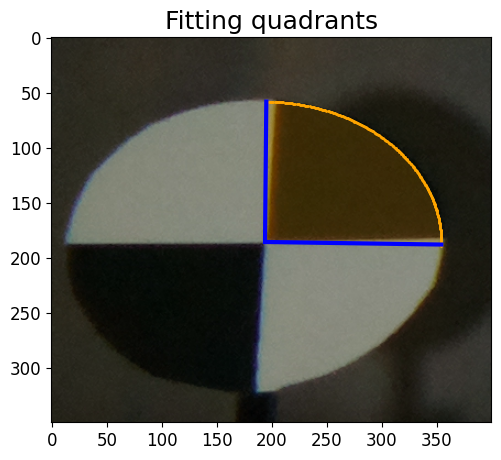

In [57]:
from scipy.spatial import ConvexHull, convex_hull_plot_2d
img = img_3[0]
pts = get_contour(img, threshold = 115, show = False, approx = False, single_region = True)
xy_ellipse, xy_horizontal, xy_vertical = get_quadrant_ellipse(pts, quadrant = 1)
xy_contour = np.concatenate([xy_ellipse, xy_horizontal, xy_vertical], axis = 0)
xy_contour = xy_contour[ConvexHull(xy_contour).vertices]
# xy_ellipse = get_full_ellipse(pts)

plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.scatter(xy_ellipse[:,0], xy_ellipse[:,1], color = colors[0], s = 1)
plt.plot(xy_horizontal[:,0], xy_horizontal[:,1], c = 'b', linewidth = 3)
plt.plot(xy_vertical[:,0], xy_vertical[:,1], c = 'b', linewidth = 3)
plt.fill(xy_contour[:,0], xy_contour[:,1], color = colors[0], alpha = 0.2)
plt.title('Fitting quadrants')

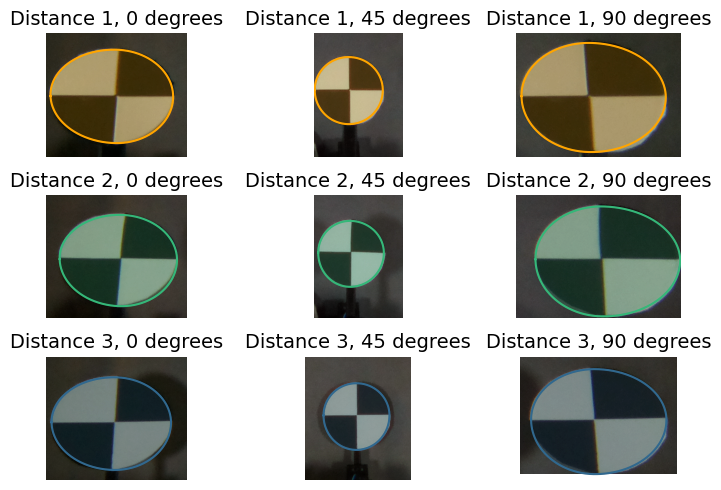

In [64]:
img_y = 850
img_x = [400, 1175, 1850]

y_offset = np.zeros((3, 3))
x_offset = np.zeros((3, 3))

x_offset[:, :] = 900
y_offset[:, 0] = 400
y_offset[:, 1] = 1200
y_offset[:, 2] = 1850

session = '240401'

image_1_00 = os.path.join(calibration_folder, session, 'distance_1_00.jpg')
image_1_45 = os.path.join(calibration_folder, session, 'distance_1_45.jpg')
image_1_90 = os.path.join(calibration_folder, session, 'distance_1_90.jpg')
image_1 = [image_1_00, image_1_45, image_1_90]

img_1_00 = cv2.imread(image_1_00)[850:1200, 400:800, :]
img_1_45 = cv2.imread(image_1_45)[850:1200, 1200:1450, :]
img_1_90 = cv2.imread(image_1_90)[850:1150, 1850:2250, :]
img_1 = [img_1_00, img_1_45, img_1_90]

image_2_00 = os.path.join(calibration_folder, session, 'distance_2_00.jpg')
image_2_45 = os.path.join(calibration_folder, session, 'distance_2_45.jpg')
image_2_90 = os.path.join(calibration_folder, session, 'distance_2_90.jpg')
image_2 = [image_2_00, image_2_45, image_2_90]

img_2_00 = cv2.imread(image_2_00)[850:1200, 400:800, :]
img_2_45 = cv2.imread(image_2_45)[850:1200, 1200:1450, :]
img_2_90 = cv2.imread(image_2_90)[850:1150, 1850:2250, :]
img_2 = [img_2_00, img_2_45, img_2_90]

image_3_00 = os.path.join(calibration_folder, session, 'distance_3_00.jpg')
image_3_45 = os.path.join(calibration_folder, session, 'distance_3_45.jpg')
image_3_90 = os.path.join(calibration_folder, session, 'distance_3_90.jpg')
image_3 = [image_3_00, image_3_45, image_3_90]

img_3_00 = cv2.imread(image_3_00)[850:1200, 400:800, :]
img_3_45 = cv2.imread(image_3_45)[850:1200, 1150:1450, :]
img_3_90 = cv2.imread(image_3_90)[850:1150, 1850:2250, :]
img_3 = [img_3_00, img_3_45, img_3_90]

fig, ax = plt.subplots(3, 3, figsize=(8, 5))
ax[0, 0].imshow(img_1[0])
ellipse = get_full_ellipse(get_contour(img_1[0], threshold = 115, show = False, approx = False, single_region = True))
ax[0,0].plot(ellipse[:,0], ellipse[:,1], color = colors[0])
ax[0,0].fill(ellipse[:,0], ellipse[:,1], color = colors[0], alpha = 0.2)
ax[0,0].set_title('Distance 1, 0 degrees', fontsize = 14)

ax[0, 1].imshow(img_1[1])
ellipse = get_full_ellipse(get_contour(img_1[1], threshold = 115, show = False, approx = False, single_region = True))
ax[0,1].plot(ellipse[:,0], ellipse[:,1], color = colors[0])
ax[0,1].fill(ellipse[:,0], ellipse[:,1], color = colors[0], alpha = 0.2)
ax[0,1].set_title('Distance 1, 45 degrees', fontsize = 14)

ax[0, 2].imshow(img_1[2])
ax[0,2].set_title('Distance 1, 90 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_1[2], threshold = 115, show = False, approx = False, single_region = True))
ax[0,2].plot(ellipse[:,0], ellipse[:,1], color = colors[0])
ax[0,2].fill(ellipse[:,0], ellipse[:,1], color = colors[0], alpha = 0.2)


ax[1, 0].imshow(img_2[0])
ax[1,0].set_title('Distance 2, 0 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_2[0], threshold = 115, show = False, approx = False, single_region = True))
ax[1,0].plot(ellipse[:,0], ellipse[:,1], color = colors[1])
ax[1,0].fill(ellipse[:,0], ellipse[:,1], color = colors[1], alpha = 0.2)

ax[1, 1].imshow(img_2[1])
ax[1,1].set_title('Distance 2, 45 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_2[1], threshold = 115, show = False, approx = False, single_region = True))
ax[1,1].plot(ellipse[:,0], ellipse[:,1], color = colors[1])
ax[1,1].fill(ellipse[:,0], ellipse[:,1], color = colors[1], alpha = 0.2)

ax[1, 2].imshow(img_2[2])
ax[1,2].set_title('Distance 2, 90 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_2[2], threshold = 115, show = False, approx = False, single_region = True))
ax[1,2].plot(ellipse[:,0], ellipse[:,1], color = colors[1])
ax[1,2].fill(ellipse[:,0], ellipse[:,1], color = colors[1], alpha = 0.2)


ax[2, 0].imshow(img_3[0])
ax[2,0].set_title('Distance 3, 0 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_3[0], threshold = 115, show = False, approx = False, single_region = True))
ax[2,0].plot(ellipse[:,0], ellipse[:,1], color = colors[2])
ax[2,0].fill(ellipse[:,0], ellipse[:,1], color = colors[2], alpha = 0.2)

ax[2, 1].imshow(img_3[1])
ax[2,1].set_title('Distance 3, 45 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_3[1], threshold = 115, show = False, approx = False, single_region = True))
ax[2,1].plot(ellipse[:,0], ellipse[:,1], color = colors[2])
ax[2,1].fill(ellipse[:,0], ellipse[:,1], color = colors[2], alpha = 0.2)


ax[2, 2].imshow(img_3[2])
ax[2,2].set_title('Distance 3, 90 degrees', fontsize = 14)
ellipse = get_full_ellipse(get_contour(img_3[2], threshold = 115, show = False, approx = False, single_region = True))
ax[2,2].plot(ellipse[:,0], ellipse[:,1], color = colors[2])
ax[2,2].fill(ellipse[:,0], ellipse[:,1], color = colors[2], alpha = 0.2)


# set all axis to be off
for axi in ax.flatten():
    axi.axis('off')
    
plt.tight_layout()

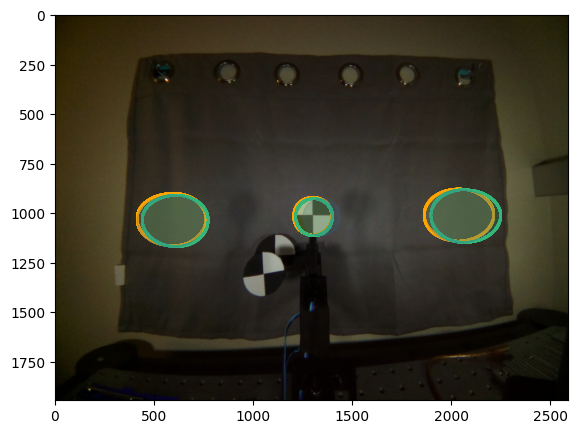

In [5]:
# get theta of all the points in the ellipse
colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']

plt.figure(figsize = (10, 5))
plt.imshow(cv2.imread(image_1[1]))

for i, img in enumerate(img_1):
    
    pts = get_contour(img, threshold = 115, show = False, approx = False, single_region = True)
    xy_ellipse = get_full_ellipse(pts)
    xy_ellipse[:,1] += 850
    xy_ellipse[:,0] += y_offset[0, i]
    
    plt.scatter(xy_ellipse[:,0], xy_ellipse[:,1], color = colors[0], s = 1)
    plt.fill(xy_ellipse[:,0], xy_ellipse[:,1], color = colors[0], alpha = 0.2)

for i, img in enumerate(img_2):

    pts = get_contour(img, threshold = 115, show = False, approx = False, single_region = True)
    xy_ellipse = get_full_ellipse(pts)
    xy_ellipse[:,1] += 850
    xy_ellipse[:,0] += y_offset[0, i]

    plt.scatter(xy_ellipse[:,0], xy_ellipse[:,1], color = colors[1], s = 1)
    plt.fill(xy_ellipse[:,0], xy_ellipse[:,1], color = colors[1], alpha = 0.2)

for i, img in enumerate(img_3):

    pts = get_contour(img, threshold = 115, show = False, approx = False, single_region = True)
    xy_ellipse = get_full_ellipse(pts)
    xy_ellipse[:,1] += 850
    xy_ellipse[:,0] += y_offset[0, i]

    plt.fill(xy_ellipse[:,0], xy_ellipse[:,1], color = colors[2], alpha = 0.2)

In [7]:
# for every image get the points enclosed by the ellipse

# get the points enclosed by the ellipse
values_1 = []
for img in img_1:
    values_ = get_points_enclosed_by_ellipse(img, threshold = 115)
    values_1.append(values_)
    
values_2 = []
for img in img_2:
    values_ = get_points_enclosed_by_ellipse(img, threshold = 115)
    values_2.append(values_)
    
values_3 = []
for img in img_3:
    values_ = get_points_enclosed_by_ellipse(img, threshold=115)
    values_3.append(values_)

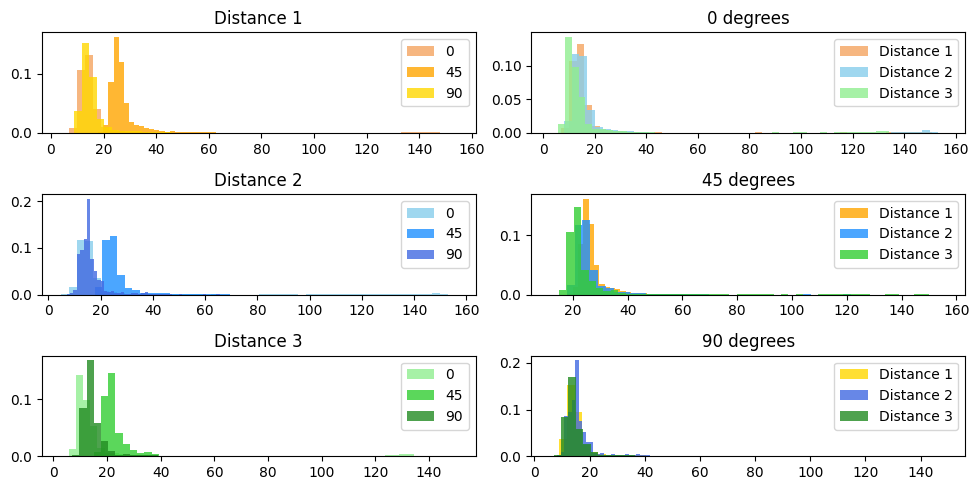

In [8]:
legend = ['0', '45', '90']
colors = ['sandybrown', 'orange', 'gold']
fig, ax = plt.subplots(3, 2, figsize=(10, 5))
for i, values_ in enumerate(values_1):
    ax[0, 0].hist(values_, bins = 50, density = True, label = legend[i], color = colors[i], alpha = 0.8)
    ax[0, 0].legend()
    ax[0, 0].set_title('Distance 1')
    
colors = ['skyblue', 'dodgerblue', 'royalblue']
for i, values_ in enumerate(values_2):
    ax[1, 0].hist(values_, bins = 50, density = True, label = legend[i], color = colors[i], alpha = 0.8)
    ax[1, 0].legend()
    ax[1, 0].set_title('Distance 2')
    
colors = ['lightgreen', 'limegreen', 'forestgreen']
for i, values_ in enumerate(values_3):
    ax[2, 0].hist(values_, bins = 50, density = True, label = legend[i], color = colors[i], alpha = 0.8)
    ax[2, 0].legend()
    ax[2, 0].set_title('Distance 3')

labels = ['Distance 1', 'Distance 2', 'Distance 3']

ax[0, 1].hist(values_1[0], bins = 50, density = True, label = '0', color = 'sandybrown', alpha = 0.8)
ax[0, 1].hist(values_2[0], bins = 50, density = True, label = '45', color = 'skyblue', alpha = 0.8)
ax[0, 1].hist(values_3[0], bins = 50, density = True, label = '90', color = 'lightgreen', alpha = 0.8)
ax[0, 1].legend(labels = labels)
ax[0, 1].set_title('0 degrees')

ax[1, 1].hist(values_1[1], bins = 50, density = True, label = '0', color = 'orange', alpha = 0.8)
ax[1, 1].hist(values_2[1], bins = 50, density = True, label = '45', color = 'dodgerblue', alpha = 0.8)
ax[1, 1].hist(values_3[1], bins = 50, density = True, label = '90', color = 'limegreen', alpha = 0.8)
ax[1, 1].legend(labels = labels)
ax[1, 1].set_title('45 degrees')

ax[2, 1].hist(values_1[2], bins = 50, density = True, label = '0', color = 'gold', alpha = 0.8)
ax[2, 1].hist(values_2[2], bins = 50, density = True, label = '45', color = 'royalblue', alpha = 0.8)
ax[2, 1].hist(values_3[2], bins = 50, density = True, label = '90', color = 'forestgreen', alpha = 0.8)
ax[2, 1].legend(labels = labels)
ax[2, 1].set_title('90 degrees')

plt.tight_layout()

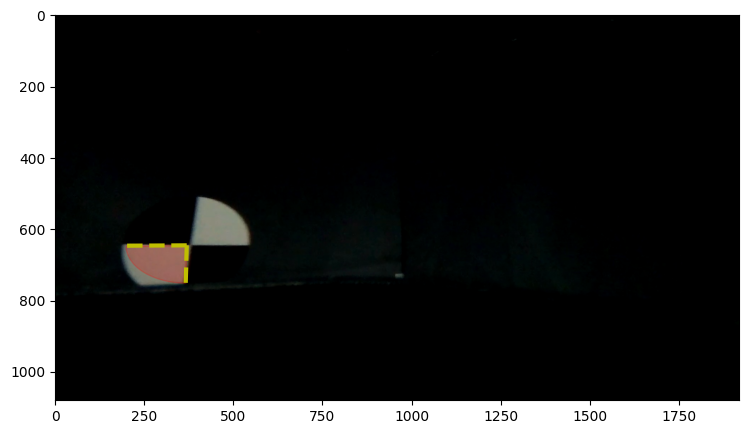

In [41]:
pts = get_contour(img, threshold = 115, show = False, approx = False, single_region = True)
xy_ellipse, xy_horizontal, xy_vertical = get_quadrant_ellipse(pts, quadrant = 3)
xy_contour = np.concatenate([xy_ellipse, xy_horizontal, xy_vertical], axis = 0)
# xy_contour = xy_contour[ConvexHull(xy_contour).vertices]
# xy_ellipse = get_full_ellipse(pts)

plt.figure(figsize=(10, 5))
plt.imshow(img)
# plt.scatter(xy_ellipse[:,0], xy_ellipse[:,1], color = 'r', s = 1)
plt.plot(xy_horizontal[:,0], xy_horizontal[:,1], c = 'y', linestyle = '--', linewidth = 3)
plt.plot(xy_vertical[:,0], xy_vertical[:,1], c = 'y', linestyle = '--', linewidth = 3)
plt.fill(xy_contour[:,0], xy_contour[:,1], color = 'r', alpha = 0.2)

638.0 664.0


(-0.015833777855230973, 647.8492890887061)

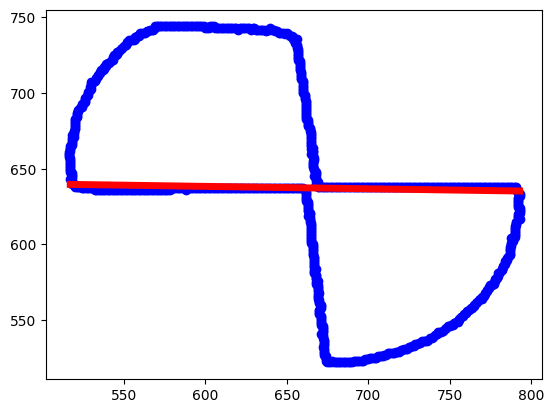

In [164]:
pts = get_contour(imgs[55], threshold = 30, show = False, approx = False, single_region = True)
get_axis_line(pts, axis_name = 'x', show=True)


638.0 664.0
664.0 638.0
638.0 664.0
664.0 638.0
638.0 664.0
664.0 638.0
638.0 664.0
664.0 638.0
664.0 638.0
638.0 664.0


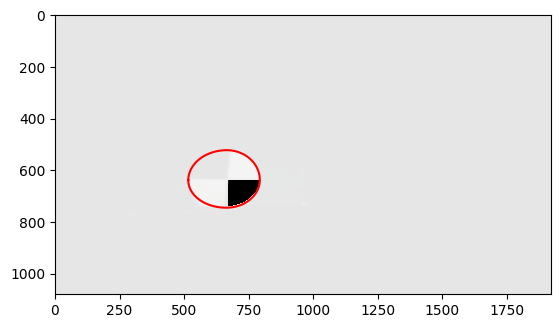

In [166]:
# get the points enclosed by the ellipse
values = get_points_enclosed_by_ellipse(imgs[55], threshold = 30, show = True, quadrant = 4)

# Reading video frames

array([ 2.,  7., 11., ..., 39., 49., 45.])

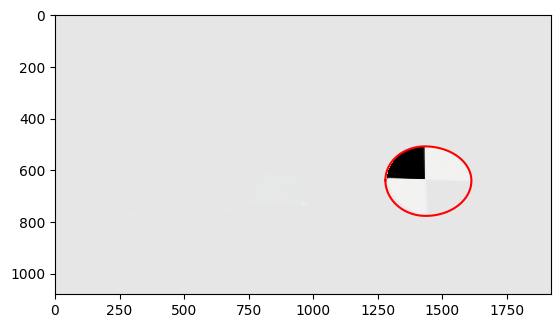

In [127]:
get_points_enclosed_by_ellipse(imgs_far[15], threshold = 30, show = True, quadrant = 2)

# Get contour

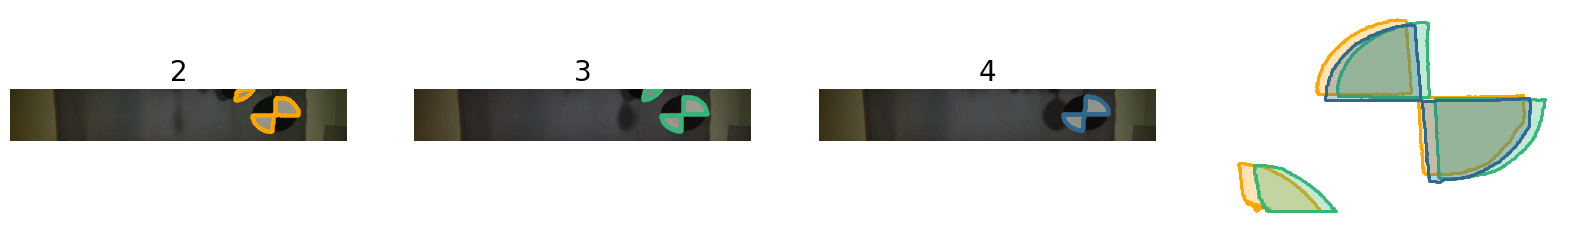

In [40]:
colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']

img_1 = cv2.imread(image_1)[roi[0]:roi[1], roi[2]:roi[3], :]
img_2 = cv2.imread(image_2)[roi[0]:roi[1], roi[2]:roi[3], :]
# img_3 = cv2.imread(image_3)[roi[0]:roi[1], roi[2]:roi[3], :]

# cnt_1 = get_cnt(img_1, threshold = 240, show = True)
pts_1 = get_cnt(img_1, threshold = 115, show = False, single_region = False)
pts_2 = get_cnt(img_2, threshold = 115, show = False, single_region = False)
pts_3 = get_cnt(img_3, threshold = 115, show = False, single_region = False)

pts = [pts_1, pts_2, pts_3]

f, axes = plt.subplots(1, 4, figsize=(20, 10))

img_1 = cv2.imread(image_1)[roi[0]:roi[1], roi[2]:roi[3], :]
axes[0].set_title('2', fontsize = 20)
axes[0].imshow(img_1)
axes[0].scatter(get_points(pts_1)[:,0],get_points(pts_1)[:,1], color = colors[0], s = 2)

img_2 = cv2.imread(image_2)[roi[0]:roi[1], roi[2]:roi[3], :]
axes[1].set_title('3', fontsize = 20)
axes[1].imshow(img_2)
axes[1].scatter(get_points(pts_2)[:,0],get_points(pts_2)[:,1], color = colors[1], s = 2)

img_3 = cv2.imread(image_3)[roi[0]:roi[1], roi[2]:roi[3], :]
axes[2].set_title('4', fontsize = 20)
axes[2].imshow(img_3)
axes[2].scatter(get_points(pts_3)[:,0], get_points(pts_3)[:,1], color = colors[2], s = 2)

ax = axes[3]
for pts_image, color in zip(pts, colors):
    if len(pts_image) > 1:
        for single_pts in pts_image:
            ax.scatter(single_pts[:,0], single_pts[:,1], color = color, s = 1)
            ax.fill(single_pts[:,0], single_pts[:,1], color = color, alpha=0.3)
    else:
        pts_image = pts_image[0]
        ax.scatter(pts_image[:,0], pts_image[:,1], color = color, s = 1)
        ax.fill(pts_image[:,0], pts_image[:,1], color = color, alpha=0.3)
        
for axi in axes:
    # ax.set_xlim(0, 250)
    # ax.set_ylim(0, 250)
    axi.set_aspect('equal', adjustable='box')
    axi.axis('off')
    axi.invert_yaxis()

In [173]:
def fit_ellipse(pts, show = True):
    
    m_horizontal, b_horizontal = get_axis_line(pts, axis_name = 'x')
    m_vertical, b_vertical = get_axis_line(pts, axis_name = 'y')
    pts_far = pts[np.logical_and(np.abs(pts[:,0] - ((pts[:,1] -b_vertical)/m_vertical)) > 20, np.abs(pts[:,1] - (m_horizontal*pts[:,0] + b_horizontal)) > 20)]
    
    # Extract x coords and y coords of the ellipse as column vectors
    X = pts_far[:,0:1]
    Y = pts_far[:,1:]
    
    # Formulate and solve the least squares problem ||Ax - b ||^2
    A = np.hstack([X**2, X * Y, Y**2, X, Y])
    b = np.ones_like(X)
    x = np.linalg.lstsq(A, b, rcond=None)[0].squeeze()

    # Print the equation of the ellipse in standard form
    print('The ellipse is given by {0:.3}x^2 + {1:.3}xy+{2:.3}y^2+{3:.3}x+{4:.3}y = 1'.format(x[0], x[1],x[2],x[3],x[4]))

    # Plot the noisy data
    plt.scatter(X, Y, label='Data Points')
    
    # Plot the least squares ellipse
    x_coord = np.linspace(0,250,300)
    y_coord = np.linspace(0,250,300)
    X_coord, Y_coord = np.meshgrid(x_coord, y_coord)
    Z_coord = x[0] * X_coord ** 2 + x[1] * X_coord * Y_coord + x[2] * Y_coord**2 + x[3] * X_coord + x[4] * Y_coord
    cs = plt.contour(X_coord, Y_coord, Z_coord, levels=[1], colors='r', linewidths=2)
    
    plt.legend()
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Least Squares Ellipse Fit')
    plt.gca().invert_yaxis()
    plt.gca().set_aspect('equal', adjustable='box')
    
    if show:
        plt.show()
    else:
        plt.close()
        
    return cs.collections[0].get_paths()[0].vertices, x

(array([    56.0473553 , -15302.36665744]), array([422788.90501244]), 2, array([1.41421330e+00, 8.58806153e-04]), 3.9968028886505635e-14)


(0.0, 500.0)

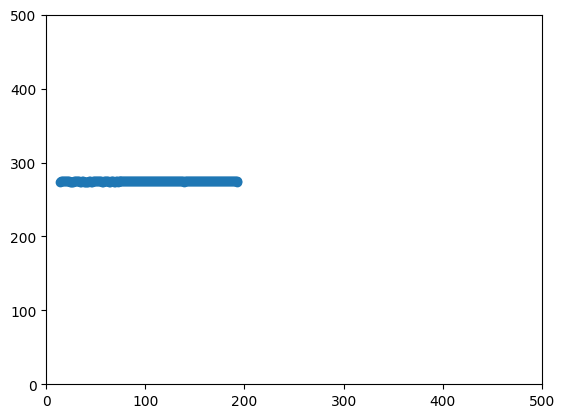

In [185]:
img = cv2.imread(image_1)[750:1200, 400:800, :]
pts = get_cnt(img, threshold = 100, show = False, approx = False, single_region = True)

axis = 1
most_common = np.median(pts[:, axis])
   
epsilon_vec = np.arange(2, 10, 1)
res = []
for e in epsilon_vec:
    
    close_pts_to_axis = pts[np.logical_and(pts[:, axis] > most_common - e , pts[:, axis] < most_common + e )]
    
    try:
        if axis == 0:
            _, res_, _, _, _ = np.polyfit(close_pts_to_axis[:,1], close_pts_to_axis[:,0], 1, full = True)
        else:
            _, res_, _, _, _ = np.polyfit(close_pts_to_axis[:,0], close_pts_to_axis[:,1], 1, full = True)
        
    except:
        print('Not enough points to fit a line')
       # stop the loop if there are not enough points to fit a line
        break
    
    res.append(res_)

# get the epsilon with the minimum residual
epsilon = epsilon_vec[np.argmin(res)]
close_pts_to_axis = pts[np.logical_and(pts[:, axis] > most_common - epsilon, pts[:, axis] < most_common + epsilon)]


print(np.polyfit(close_pts_to_axis[:,1], close_pts_to_axis[:,0], 1, full = True))

plt.figure()
plt.scatter(close_pts_to_axis[:,0], close_pts_to_axis[:,1])

# set limits
plt.xlim(0, 500)
plt.ylim(0, 500)
# plt.scatter(pts[:,0], pts[:,1], color = 'r', s = 1)

[array([17.45881656]), array([24.46798165]), array([75.25396974]), array([197.44178636]), array([696.56691678]), array([796.0280303]), array([930.73531442]), array([1108.21546916])]
[array([315441.16585448]), array([526199.84803755]), array([712658.30714953]), array([891972.70181353]), array([1051781.73409517]), array([1185050.22939979]), array([1325196.75546026]), array([1458399.01042381])]
Theta: 75.63325225207157


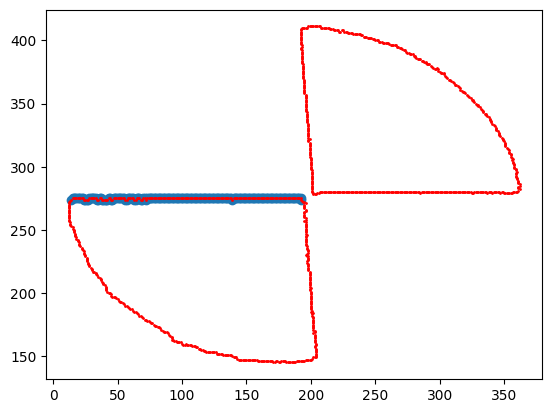

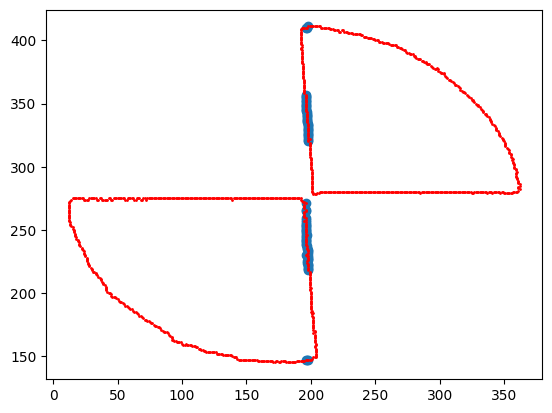

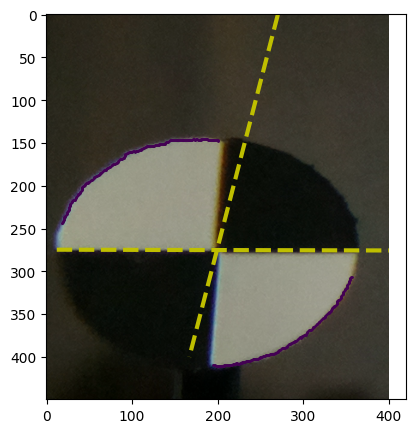

In [172]:
img = cv2.imread(image_1)[750:1200, 400:800, :]
pts = get_cnt(img, threshold = 100, show = False, approx = False, single_region = True)

m_horizontal, b_horizontal = get_axis_line(pts, axis_name = 'x')
m_vertical, b_vertical = get_axis_line(pts, axis_name = 'y')
x_center, y_center = get_center(m_horizontal, b_horizontal, m_vertical, b_vertical)

min_x = np.min(pts[:,0])
# find the point in pts closer to x_center
max_x = 400

min_y = 0
max_y = 400

x_horizontal = np.linspace(min_x, max_x, 1000)
y_horizontal = m_horizontal * x_horizontal + b_horizontal

y_vertical = np.linspace(min_y, max_y, 1000)
x_vertical = (y_vertical - b_vertical) / m_vertical

print('Theta:', np.degrees(np.arctan(m_horizontal-m_vertical/(1+m_horizontal*m_vertical))))

# m_horizontal, b_horizontal = get_axis_line(pts, axis_name = 'x')
# m_vertical, b_vertical = get_axis_line(pts, axis_name = 'y')
# pts_far = pts[np.logical_and(np.abs(pts[:,0] - ((pts[:,1] -b_vertical)/m_vertical)) > 30, np.abs(pts[:,1] - (m_horizontal*pts[:,0] + b_horizontal)) > 30)]

plt.figure(figsize=(10, 5))
plt.imshow(img)
plt.scatter(pts_far[:,0], pts_far[:,1], color = colors[3], s = 1)
plt.plot(x_horizontal, y_horizontal, c = 'y', linestyle = '--', linewidth = 3)
plt.plot(x_vertical, y_vertical, c = 'y', linestyle = '--', linewidth = 3)
# plt.scatter(x_center, y_center, s = 200, c = 'y', marker = 'x')
# plt.gca().set_aspect('equal', adjustable='box')

(array([5.6300e+03, 2.0019e+04, 4.8139e+04, 6.1205e+04, 2.3345e+04,
        1.2484e+04, 1.6689e+04, 1.7305e+04, 2.3070e+04, 1.6752e+04,
        3.1619e+04, 3.9346e+04, 2.8674e+04, 5.1341e+04, 3.7193e+04,
        7.1063e+04, 5.0083e+04, 1.1899e+04, 3.8730e+03, 1.0980e+03,
        1.1990e+03, 1.0940e+03, 7.1400e+02, 9.5800e+02, 6.8100e+02,
        8.7800e+02, 8.4500e+02, 5.5600e+02, 8.8000e+02, 7.1600e+02,
        9.4500e+02, 1.0140e+03, 9.2200e+02, 1.3260e+03, 1.0580e+03,
        2.4010e+03, 6.9810e+03, 1.6831e+04, 1.6969e+04, 4.3140e+03,
        6.4810e+03, 1.8055e+04, 3.1208e+04, 2.8382e+04, 3.1800e+03,
        4.1600e+02, 1.3600e+02, 2.8000e+01, 3.0000e+00, 2.0000e+00]),
 array([  0. ,   3.6,   7.2,  10.8,  14.4,  18. ,  21.6,  25.2,  28.8,
         32.4,  36. ,  39.6,  43.2,  46.8,  50.4,  54. ,  57.6,  61.2,
         64.8,  68.4,  72. ,  75.6,  79.2,  82.8,  86.4,  90. ,  93.6,
         97.2, 100.8, 104.4, 108. , 111.6, 115.2, 118.8, 122.4, 126. ,
        129.6, 133.2, 136.8, 140.4

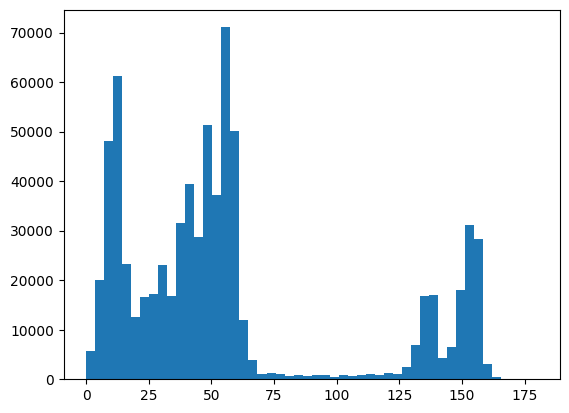

In [118]:
plt.hist(img.flatten(), bins = 50)

The ellipse is given by -8.77e-06x^2 + -6.44e-07xy+-1.5e-05y^2+0.00492x+0.00645y = 1


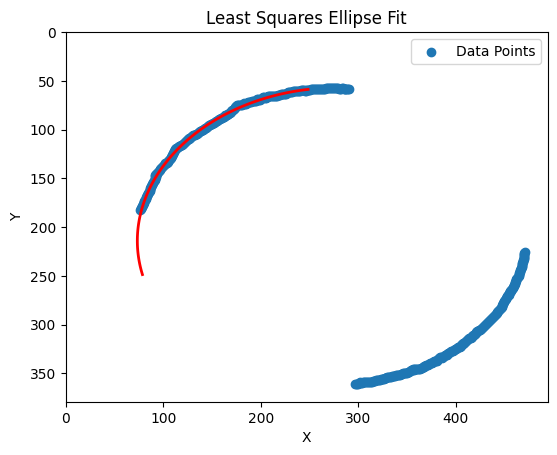

In [116]:
pts_ellipse, _ = fit_ellipse(pts, show = True)

The ellipse is given by -3.76e-07x^2 + -1.37e-07xy+5.83e-07y^2+0.00156x+-0.000932y = 1


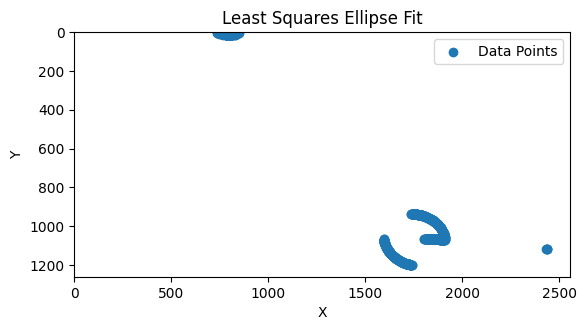

IndexError: list index out of range

In [78]:
# get the points between left and right in the x axis, but y cannot be higher or lower than 5 units of the y of left and right
img = cv2.imread(image_1)
pts = get_cnt(img, threshold = 100, show = True, approx = False, single_region = True)
pts_ellipse, _ = fit_ellipse(pts, show = True)

# get minimum x of the ellipse
min_x = np.min(pts_ellipse[:,0])
max_x = np.max(pts_ellipse[:,0])

# get minimum y of the ellipse
min_y = np.min(pts_ellipse[:,1])
max_y = np.max(pts_ellipse[:,1])

x_horizontal = np.linspace(0, 250, 1000)
m_horizontal, b_horizontal = get_axis_line(pts, axis_name = 'x')
y_horizontal = m_horizontal * x_horizontal + b_horizontal

y_vertical = np.linspace(0, 250, 1000)
m_vertical, b_vertical = get_axis_line(pts, axis_name = 'y')
x_vertical = (y_vertical - b_vertical) / m_vertical

plt.figure(figsize=(5, 5))
plt.imshow(img)
# plt.scatter(pts[:,0], pts[:,1], color = colors[3], s = 1)
plt.fill(pts[:,0], pts[:,1], color = colors[3], alpha = 0.2)
plt.plot(pts_ellipse[:,0], pts_ellipse[:,1], c = 'y', linestyle = '--', linewidth = 3)
plt.fill(pts_ellipse[:,0], pts_ellipse[:,1], color = 'b', alpha = 0.2)
plt.plot(x_horizontal, y_horizontal, c = 'y', linestyle = '--', linewidth = 3)
plt.plot(x_vertical, y_vertical, c = 'y', linestyle = '--', linewidth = 3)
# aspect ratio equal
plt.gca().set_aspect('equal', adjustable='box')
plt.axis('off')

The ellipse is given by -5.61e-05x^2 + 4.66e-06xy+-5.66e-05y^2+0.0135x+0.0121y = 1
The ellipse is given by -4.87e-05x^2 + 3.43e-06xy+-4.81e-05y^2+0.0123x+0.0107y = 1
The ellipse is given by -4.96e-05x^2 + -2.05e-07xy+-4.92e-05y^2+0.0121x+0.0117y = 1


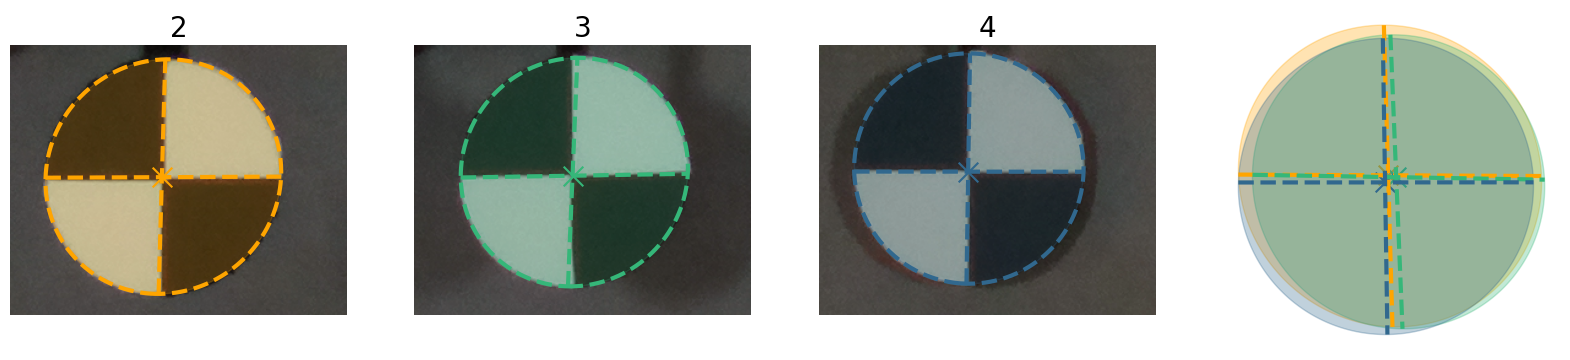

In [20]:
colors = ['orange', '#35b779', '#31688e', '#440154', 'gray']

img_1 = cv2.imread(image_1)[roi[0]:roi[1], roi[2]:roi[3], :]
img_2 = cv2.imread(image_2)[roi[0]:roi[1], roi[2]:roi[3], :]
img_3 = cv2.imread(image_3)[roi[0]:roi[1], roi[2]:roi[3], :]

images = [img_1, img_2, img_3]

# cnt_1 = get_cnt(img_1, threshold = 240, show = True)
pts_1 = get_cnt(img_1, threshold = 115, show = False, single_region = True)
pts_2 = get_cnt(img_2, threshold = 115, show = False, single_region = True)
pts_3 = get_cnt(img_3, threshold = 115, show = False, single_region = True)

pts = [pts_1, pts_2, pts_3]

ellipse_1, _ = fit_ellipse(pts_1, show = False)
ellipse_2, _ = fit_ellipse(pts_2, show = False)
ellipse_3, _ = fit_ellipse(pts_3, show = False)
ellipses = [ellipse_1, ellipse_2, ellipse_3]

f, axes = plt.subplots(1, 4, figsize=(20, 10))

for i, ax in enumerate(axes[:3]):
    
    img = images[i]
    ellipse = ellipses[i]
    
    m_horizontal, b_horizontal = get_axis_line(pts[i], axis_name = 'x')
    m_vertical, b_vertical = get_axis_line(pts[i], axis_name = 'y')
    
    x_center, y_center = get_center(m_horizontal, b_horizontal, m_vertical, b_vertical)
    
    min_x, max_x = np.min(ellipse[:,0]), np.max(ellipse[:,0])
    min_y, max_y = np.min(ellipse[:,1]), np.max(ellipse[:,1])
    
    x_horizontal = np.linspace(min_x, max_x, 1000)
    y_horizontal = m_horizontal * x_horizontal + b_horizontal
    
    y_vertical = np.linspace(min_y, max_y, 1000)
    x_vertical = (y_vertical - b_vertical) / m_vertical
    
    ax.set_title(str(axes.tolist().index(ax) + 2), fontsize = 20)
    ax.imshow(img)
    ax.plot(x_horizontal, y_horizontal, c = colors[i], linestyle = '--', linewidth = 3)
    ax.plot(x_vertical, y_vertical, c = colors[i], linestyle = '--', linewidth = 3)
    ax.scatter(x_center, y_center, s = 200, c = colors[i], marker = 'x')
    ax.plot(ellipse[:,0], ellipse[:,1], color = colors[i], linestyle = '--', linewidth = 3)
    ax.fill(ellipse[:,0], ellipse[:,1], color = colors[i], alpha = 0.2)
    
    axes[3].fill(ellipse[:,0], ellipse[:,1], color = colors[i], alpha = 0.3)
    axes[3].plot(x_horizontal, y_horizontal, c = colors[i], linestyle = '--', linewidth = 3)
    axes[3].plot(x_vertical, y_vertical, c = colors[i], linestyle = '--', linewidth = 3)
    axes[3].scatter(x_center, y_center, s = 200, c = colors[i], marker = 'x')
    
for axi in axes:
    # ax.set_xlim(0, 250)
    # ax.set_ylim(0, 250)
    axi.invert_yaxis()
    axi.set_aspect('equal', adjustable='box')
    axi.axis('off')

In [21]:
distance_x = []
distance_y = []

for ellipse in ellipses:
    
    x_min = ellipse[np.argmin(ellipse[:,0])]
    x_max = ellipse[np.argmax(ellipse[:,0])]
    y_min = ellipse[np.argmin(ellipse[:,1])]
    y_max = ellipse[np.argmax(ellipse[:,1])]
    
    distance_x.append(np.linalg.norm(x_min - x_max))
    distance_y.append(np.linalg.norm(y_min - y_max))
    
print('Distance in x:', distance_x)
print('Distance in y:', distance_y)

# get the center for every image
centers = []
for i in range(3):
    m_horizontal, b_horizontal = get_axis_line(pts[i], axis_name = 'x')
    m_vertical, b_vertical = get_axis_line(pts[i], axis_name = 'y')
    x_center, y_center = get_center(m_horizontal, b_horizontal, m_vertical, b_vertical)
    centers.append([x_center, y_center])
    
print('Centers:', centers)


# plt.plot(ellipse_2[:,0], ellipse_2[:,1], color = colors[0])
# plt.scatter(x_min_2[0], x_min_2[1], color = colors[1], s = 100)
# plt.scatter(x_max_2[0], x_max_2[1], color = colors[2], s = 100)
# plt.scatter(y_min_2[0], y_min_2[1], color = colors[3], s = 100)
# plt.scatter(y_max_2[0], y_max_2[1], color = colors[4], s = 100)

# print(7.6/distance_x)

Distance in x: [192.53097622671805, 185.5245916891574, 187.25589276947318]
Distance in y: [191.63464747453403, 186.6916138631781, 187.98239291900484]
Centers: [[123.4733779555057, 111.6805591726666], [128.60465185820627, 112.88853778371697], [121.5136789484945, 116.19790751380913]]


In [22]:
def get_points_enclosed_by_ellipse(img):
    
    pts = get_cnt(img, threshold = 150, show = False, approx = False, single_region = True)
    pts_ellipse, _ = fit_ellipse(pts, show = False)
    
    # mask the image by the points given in pts_ellipse
    mask = np.zeros_like(img)
    cv2.fillPoly(mask, [pts_ellipse.astype(int)], (255,255,255))
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
    
    # mask img by mask
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = cv2.bitwise_and(img, img, mask = mask)
    
    values = img[img != 0]
    
    return img, values

The ellipse is given by -4.74e-05x^2 + 2.18e-06xy+-4.7e-05y^2+0.0121x+0.0106y = 1


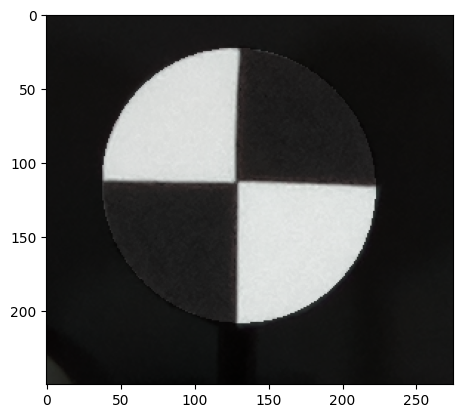

In [23]:
img, values = get_points_enclosed_by_ellipse(img_4)
plt.imshow(img, cmap = 'gray')
plt.imshow(img_4, alpha = 0.3, cmap = 'gray')

The ellipse is given by -4.48e-05x^2 + -1.34e-05xy+-4.02e-05y^2+0.0124x+0.0111y = 1
The ellipse is given by -4.74e-05x^2 + 2.18e-06xy+-4.7e-05y^2+0.0121x+0.0106y = 1
The ellipse is given by -4.87e-05x^2 + -5.14e-07xy+-4.85e-05y^2+0.012x+0.0116y = 1


Text(0.5, 1.0, 'Histogram of values enclosed by the ellipse')

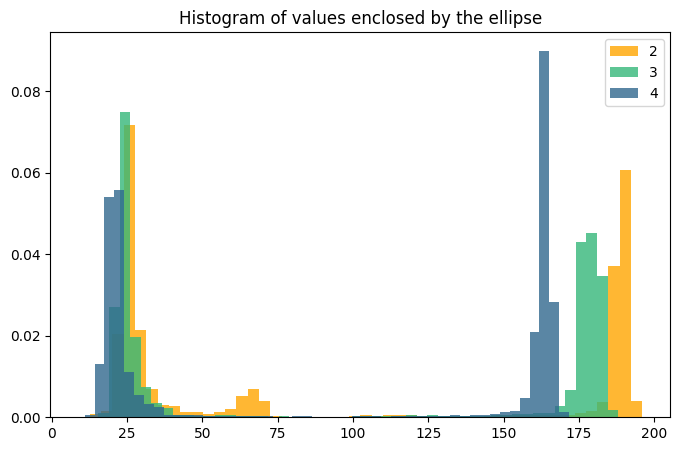

In [28]:
# make a histogram for every image
values = []
for img in images:
    _, values_ = get_points_enclosed_by_ellipse(img)
    # remove values higher than 100
    values_ = values_
    values.append(values_)
    
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
for i, values_ in enumerate(values):
    ax.hist(values_, bins = 50, density = True, label = str(i+2), color = colors[i], alpha = 0.8)
ax.legend()
ax.set_title('Histogram of values enclosed by the ellipse')


# New Video

In [ ]:
video_file = r'D:\data-distance-coding-project\calibration\240413\video_calibration_240413.h264'

